# A sufficient direction for weight refinement
A small native Python illustration. The samples fill two dimensions, but the true density ratio depends on one linear direction.
This notebook uses 100 kernel centers and searches both possible dimensions. The full study uses 35 cases and five dataset seeds; this illustration is not its aggregate result.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
from subspace_refinement import D3LHSS
from subspace_refinement.data import dataset

In [2]:
case = dict(n=1000, d=2, seed=11, scenario="one_latent_direction")
data = dataset(case, test_size=6000)
with threadpool_limits(2):
    model = D3LHSS(n_centers=100, max_dim=2).fit(
        data.train_x[data.train_w > 0], data.train_x[data.train_w < 0])
    prediction = model.predict_refinement(data.test_x, data.mass_ratio)
error = np.sqrt(np.mean((prediction - data.true_c)**2))
print(f"Training events: {len(data.train_x)}; independent test events: {len(data.test_x)}")
print(f"Selected dimension: {model.selected_dim_}; independent c-RMSE: {error:.4f}")

Training events: 800; independent test events: 6000
Selected dimension: 2; independent c-RMSE: 0.1279


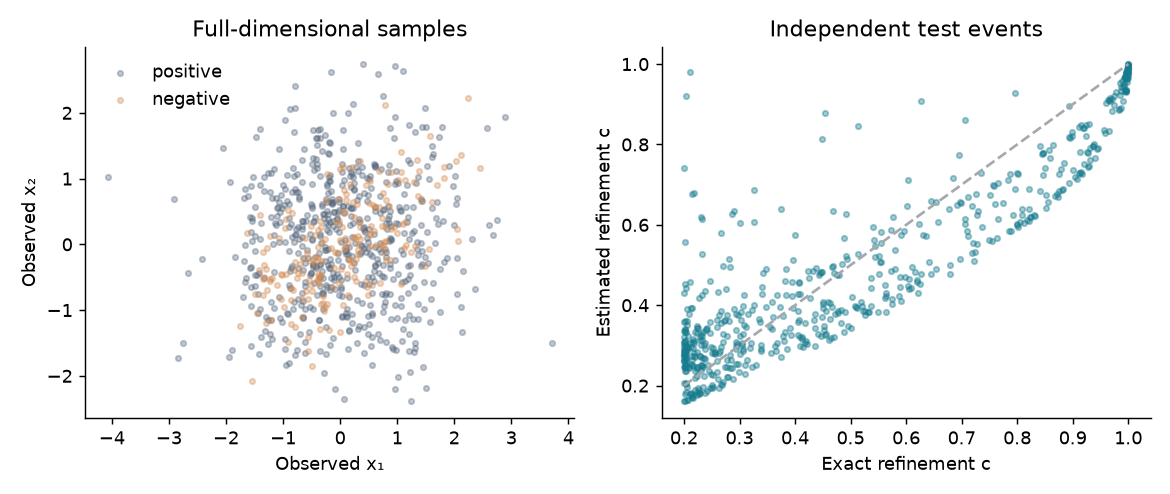

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for mask, color, label in [(data.train_w > 0, "#52647a", "positive"),
                           (data.train_w < 0, "#d38b51", "negative")]:
    axes[0].scatter(*data.train_x[mask].T, s=9, alpha=.35, color=color, label=label)
axes[0].set(xlabel="Observed x₁", ylabel="Observed x₂", title="Full-dimensional samples")
axes[0].legend(frameon=False)
axes[1].scatter(data.true_c[::10], prediction[::10], s=9, alpha=.4, color="#167b8e")
axes[1].plot([.2, 1], [.2, 1], "--", color="#a5a9ae")
axes[1].set(xlabel="Exact refinement c", ylabel="Estimated refinement c", title="Independent test events")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## What to take from the example
The learned dimension is selected from data. A sufficient one-dimensional direction exists by construction, so this is a controlled test of the hypothesis rather than evidence that collider data have this structure.
For aggregate results, uncertainty across seeds and failure cases, see the repository README and results report.